In [1]:
import os
import re
import json
import glob
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score

INPUT = "/kaggle/input/datasets/nocturnalnerd18"
OUT_DIR = "/kaggle/working"
SOURCES = {"llava": "atp-llava-noising", "qwen": "atp-qwen-noising", "intern": "atp-intern-noising"}
TAU = 1.0
TAUS = [0.5, 1.0, 2.0]
MIN_WORD = 8
N_BOOT = 1000
rng = np.random.default_rng(1)
MODES = ["image-flipped", "image-amplified", "prior-only", "under-rescued"]


def batch_number(path):
    return int(re.search(r"_batch_(\d+)\.pt$", path).group(1))


with open(f"{INPUT}/vlm-questions/all_questions.json") as f:
    all_questions = json.load(f)
qtext = {q["question_id"]: q["question_text"] for q in all_questions}

FIELDS = ("question_id", "hallucination_type", "stratum", "group", "source", "split", "sign", "delta_clean", "delta_corrupt", "TE")
FRAMES = {}
for model_, slug in SOURCES.items():
    paths = sorted(glob.glob(f"{INPUT}/{slug}/**/*_batch_*.pt", recursive=True), key=lambda p: (os.path.basename(p).split("_batch_")[0], batch_number(p)))
    if not paths:
        print(f"{model_}: {slug} not attached, skipped")
        continue
    rows, seen = [], set()
    for path in paths:
        for e in torch.load(path):
            if e["ok"] and e["question_id"] not in seen:
                seen.add(e["question_id"])
                rows.append({k: e[k] for k in FIELDS})
    d = pd.DataFrame(rows)
    d["P"] = d.delta_corrupt
    d["V"] = d.delta_clean - d.delta_corrupt
    print(f"{model_}: {len(paths)} batch files, {len(d)} ok entries, max |TE - (clean - corrupt)| {float((d.TE - d.V).abs().max()):.3f}")
    FRAMES[model_] = d
    print(pd.crosstab([d.hallucination_type, d.source], d.stratum).to_string())

llava: 43 batch files, 8403 ok entries, max |TE - (clean - corrupt)| 0.000
stratum                      false_yes  true_no  true_yes
hallucination_type source                                
attribute          amber          1736     1041      1562
object             pope            194      120       180
relation           amber           145      277       327
                   reefknot       1283      579       959
qwen: 15 batch files, 2927 ok entries, max |TE - (clean - corrupt)| 0.000
stratum                      false_yes  true_no  true_yes
hallucination_type source                                
attribute          amber           113      120       180
relation           amber             4      204       133
                   reefknot       1002      399       772
intern: atp-intern-noising not attached, skipped


In [2]:
def assign(d, tau):
    mode = np.full(len(d), "", dtype=object)
    wrong = d.delta_clean.to_numpy() < 0
    V, P = d.V.to_numpy(), d.P.to_numpy()
    mode[wrong & (V < -tau) & (P >= 0)] = "image-flipped"
    mode[wrong & (V < -tau) & (P < 0)] = "image-amplified"
    mode[wrong & (np.abs(V) <= tau)] = "prior-only"
    mode[wrong & (V > tau)] = "under-rescued"
    return mode


def shares(modes, n_boot=N_BOOT):
    point = np.array([(modes == m).mean() for m in MODES])
    draws = np.stack([[(modes[i] == m).mean() for m in MODES] for i in rng.integers(0, len(modes), size=(n_boot, len(modes)))])
    return point, np.percentile(draws, 2.5, axis=0), np.percentile(draws, 97.5, axis=0)


for model_, d in FRAMES.items():
    d["mode"] = assign(d, TAU)
    fy = d[d.stratum.eq("false_yes")]
    print(f"=== {model_}: false_yes {len(fy)} questions, wrong without exception {bool((fy.delta_clean < 0).all())} ===")
    rows = []
    for (t, s), g in fy.groupby(["hallucination_type", "source"]):
        if len(g) < 10:
            continue
        p, lo, hi = shares(g["mode"].to_numpy())
        rows.append({"type/source": f"{t}/{s}", "n": len(g), **{m: f"{p[i]:.2f} [{lo[i]:.2f}, {hi[i]:.2f}]" for i, m in enumerate(MODES)}})
    print(pd.DataFrame(rows).to_string(index=False))
    print("sensitivity of the mode shares to the threshold (all false_yes):")
    sens = []
    for tau in TAUS:
        m_ = assign(fy, tau)
        sens.append({"tau": tau, **{m: round(float((m_ == m).mean()), 2) for m in MODES}})
    print(pd.DataFrame(sens).to_string(index=False))
    print("margins by stratum, prior P (corrupt) and visual V (clean minus corrupt), logits:")
    print(d.groupby("stratum")[["P", "V", "delta_clean"]].describe().loc[:, (slice(None), ["count", "25%", "50%", "75%"])].round(2).to_string())

=== llava: false_yes 3358 questions, wrong without exception True ===
      type/source    n     image-flipped   image-amplified        prior-only     under-rescued
  attribute/amber 1736 0.10 [0.08, 0.11] 0.35 [0.33, 0.37] 0.54 [0.52, 0.56] 0.01 [0.01, 0.02]
      object/pope  194 0.09 [0.05, 0.12] 0.25 [0.19, 0.31] 0.66 [0.59, 0.73] 0.01 [0.00, 0.02]
   relation/amber  145 0.02 [0.00, 0.05] 0.01 [0.00, 0.02] 0.95 [0.92, 0.99] 0.02 [0.00, 0.05]
relation/reefknot 1283 0.00 [0.00, 0.00] 0.10 [0.08, 0.11] 0.84 [0.82, 0.86] 0.06 [0.05, 0.08]
sensitivity of the mode shares to the threshold (all false_yes):
 tau  image-flipped  image-amplified  prior-only  under-rescued
 0.5           0.09             0.36        0.41           0.14
 1.0           0.06             0.23        0.68           0.03
 2.0           0.03             0.11        0.86           0.00
margins by stratum, prior P (corrupt) and visual V (clean minus corrupt), logits:
                P                         V         

In [3]:
for model_, d in FRAMES.items():
    fy = d[d.stratum.eq("false_yes") & d.hallucination_type.eq("attribute")].copy()
    if len(fy) < 30:
        continue
    fy["word"] = [re.sub(r"[^a-z\- ]", "", qtext[q].lower()).split()[-1] if re.sub(r"[^a-z\- ]", "", qtext[q].lower()).split() else "" for q in fy.question_id]
    top = fy.word.value_counts()
    top = top[top >= MIN_WORD].index[:20]
    rows = []
    for w in top:
        g = fy[fy.word.eq(w)]
        rows.append({"last word": w, "n": len(g), **{m: round(float((g["mode"] == m).mean()), 2) for m in MODES}, "median V": round(float(g.V.median()), 2), "median P": round(float(g.P.median()), 2)})
    print(f"=== {model_}: attribute false_yes by the attribute word at the end of the question (words with at least {MIN_WORD} cases) ===")
    print(pd.DataFrame(rows).to_string(index=False))
    if fy.group.nunique() <= 12:
        print(pd.crosstab(fy.group, fy["mode"], normalize="index").round(2).to_string())

if "llava" in FRAMES and "qwen" in FRAMES:
    a = FRAMES["llava"].query("stratum == 'false_yes'")[["question_id", "mode", "P", "V"]]
    b = FRAMES["qwen"].query("stratum == 'false_yes'")[["question_id", "mode", "P", "V"]]
    j = a.merge(b, on="question_id", suffixes=("_llava", "_qwen"))
    print(f"=== questions that are false_yes for both LLaVA and Qwen: {len(j)} ===")
    if len(j) >= 20:
        print(pd.crosstab(j.mode_llava, j.mode_qwen).to_string())
        kappa = cohen_kappa_score(j.mode_llava, j.mode_qwen)
        null = [cohen_kappa_score(j.mode_llava, rng.permutation(j.mode_qwen.to_numpy())) for _ in range(200)]
        print(f"agreement {float((j.mode_llava == j.mode_qwen).mean()):.2f} | kappa {kappa:.3f} | permutation null 95th percentile {np.percentile(null, 95):.3f}")
        print(f"correlation of V across the two models {float(np.corrcoef(j.V_llava, j.V_qwen)[0, 1]):.3f} | of P {float(np.corrcoef(j.P_llava, j.P_qwen)[0, 1]):.3f}")

=== llava: attribute false_yes by the attribute word at the end of the question (words with at least 8 cases) ===
last word    n  image-flipped  image-amplified  prior-only  under-rescued  median V  median P
    image 1736            0.1             0.35        0.54           0.01     -0.86     -0.43
mode       image-amplified  image-flipped  prior-only  under-rescued
group                                                               
false_yes             0.35            0.1        0.54           0.01
=== qwen: attribute false_yes by the attribute word at the end of the question (words with at least 8 cases) ===
last word   n  image-flipped  image-amplified  prior-only  under-rescued  median V  median P
    image 113           0.46             0.36        0.11           0.07     -4.25     -1.02
mode       image-amplified  image-flipped  prior-only  under-rescued
group                                                               
false_yes             0.36           0.46        0.11 

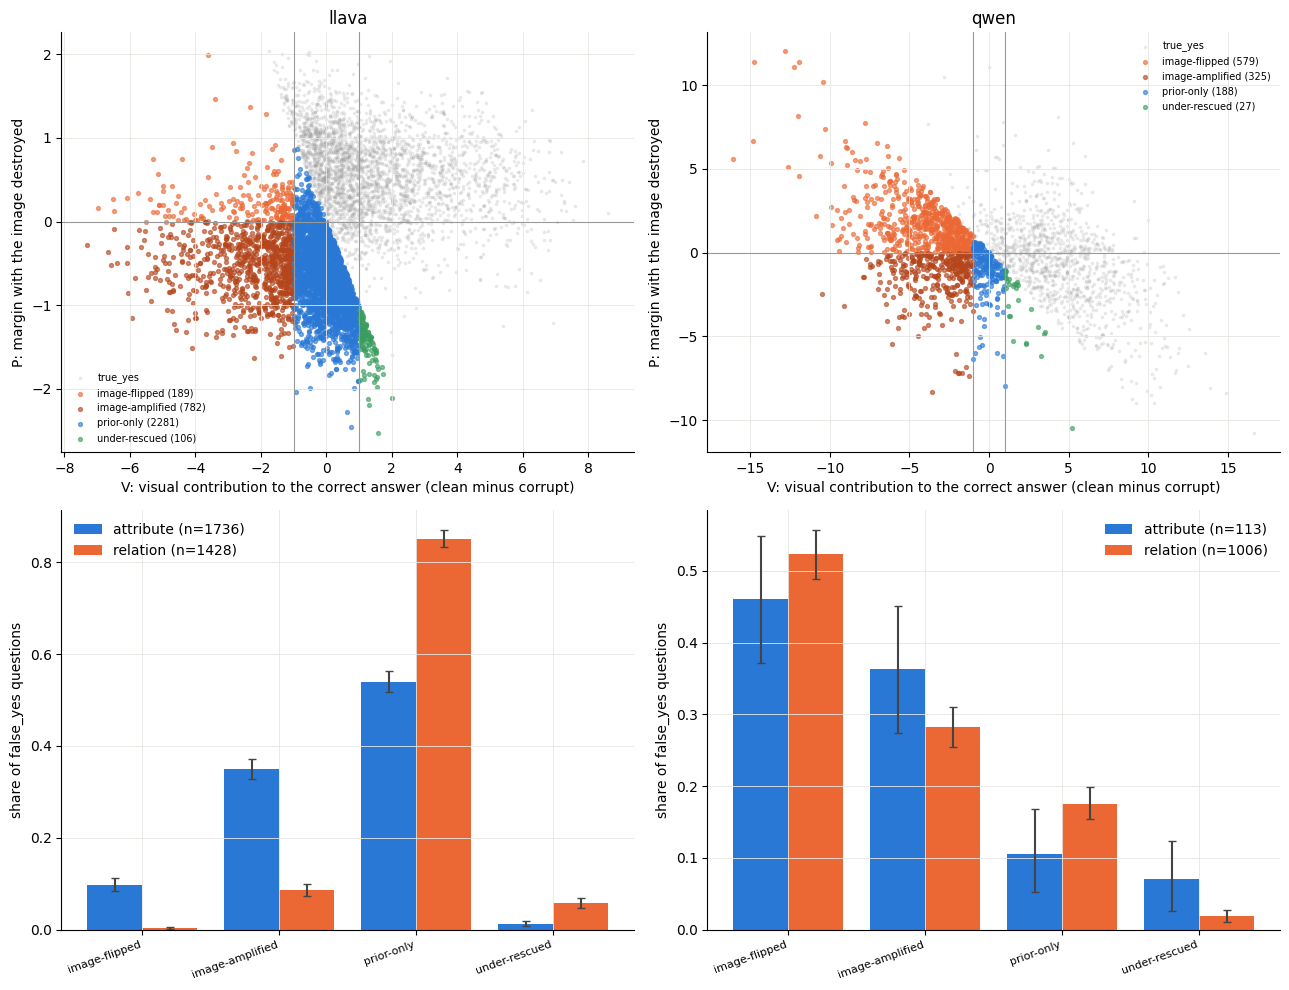

11330 rows written to hallucination_modes.csv


In [4]:
BLUE, ORANGE, GREY, GREEN = "#2a78d6", "#eb6834", "#999999", "#3a9d5d"
MODE_COLOR = {"image-flipped": ORANGE, "image-amplified": "#b5451b", "prior-only": BLUE, "under-rescued": GREEN}
fig, axes = plt.subplots(2, len(FRAMES), figsize=(6.5 * len(FRAMES), 10), squeeze=False)
for col, (model_, d) in enumerate(FRAMES.items()):
    ax = axes[0, col]
    ty = d[d.stratum.eq("true_yes")]
    ax.scatter(ty.V, ty.P, s=3, alpha=0.15, color=GREY, label="true_yes")
    fy = d[d.stratum.eq("false_yes")]
    for m in MODES:
        g = fy[fy["mode"] == m]
        ax.scatter(g.V, g.P, s=8, alpha=0.6, color=MODE_COLOR[m], label=f"{m} ({len(g)})")
    ax.axvline(-TAU, color=GREY, lw=0.8)
    ax.axvline(TAU, color=GREY, lw=0.8)
    ax.axhline(0, color=GREY, lw=0.8)
    ax.set_xlabel("V: visual contribution to the correct answer (clean minus corrupt)")
    ax.set_ylabel("P: margin with the image destroyed")
    ax.set_title(model_)
    ax.legend(frameon=False, fontsize=7)
    ax2 = axes[1, col]
    xs = np.arange(len(MODES))
    for j, (t, color) in enumerate([("attribute", BLUE), ("relation", ORANGE)]):
        g = fy[fy.hallucination_type.eq(t)]
        if len(g) < 10:
            continue
        p, lo, hi = shares(g["mode"].to_numpy())
        ax2.bar(xs + (j - 0.5) * 0.4, p, width=0.4, color=color, label=f"{t} (n={len(g)})")
        ax2.errorbar(xs + (j - 0.5) * 0.4, p, yerr=[p - lo, hi - p], fmt="none", ecolor="#444444", capsize=3)
    ax2.set_xticks(xs)
    ax2.set_xticklabels(MODES, rotation=20, ha="right", fontsize=8)
    ax2.set_ylabel("share of false_yes questions")
    ax2.legend(frameon=False)
    for a_ in (ax, ax2):
        a_.grid(color="#e5e5e2", lw=0.6)
        a_.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/hallucination_modes.png", dpi=150)
plt.show()

out = pd.concat([d.assign(model=m)[["model", "question_id", "hallucination_type", "source", "split", "stratum", "group", "P", "V", "delta_clean", "mode"]] for m, d in FRAMES.items()])
out.to_csv(f"{OUT_DIR}/hallucination_modes.csv", index=False)
print(len(out), "rows written to hallucination_modes.csv")